# Paso 5 · Modelos clásicos de Machine Learning

| | |
|---|---|
| **IDs del enunciado** | IA3.3 (lado clásico), R1, F3 |
| **Fase** | F3 · Analizar y modelar (CRISP-DM: *Modeling*) |
| **Historia** | HU-05 · Sprint S6 |
| **Entregable** | este notebook + `Back/models/resultados_clasicos.json` |

**Objetivo.** Entrenar una línea base y cuatro modelos clásicos dentro del **mismo pipeline** que usa el
modelo servido (`credit_risk.features.build_pipeline`), compararlos con validación cruzada en train y
evaluarlos **una sola vez** en test.

**Aprendizaje de la unidad (Módulo 2 · Unidad 3).** Un modelo se elige con validación cruzada sobre
train; test es un examen que se presenta una vez. El AUC mide la capacidad de *ordenar* a los clientes
por riesgo; la calibración (Brier) mide si la probabilidad *significa* lo que dice; y el umbral convierte
la probabilidad en una decisión con costos.

In [1]:
FAST = False

In [2]:
# Parameters
FAST = False


In [3]:
from credit_risk.notebook import setup

ENTORNO = setup()
ENTORNO

{'entorno': 'Jupyter local',
 'kernel': 'credit-risk',
 'semilla': 42,
 'versiones': {'python': '3.10.7',
  'pandas': '2.3.3',
  'numpy': '1.26.4',
  'matplotlib': '3.10.9',
  'seaborn': '0.13.2',
  'scikit-learn': '1.4.2',
  'duckdb': '1.5.6',
  'plotnine': '0.15.8'}}

In [4]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_validate

from credit_risk import config
from credit_risk.data import cargar_procesados, separar_xy
from credit_risk.explain import importancia_permutacion
from credit_risk.features import build_pipeline, variable_original
from credit_risk.models import catalogo, curvas, cv_estratificada, metricas, umbrales_chow
from credit_risk.reporting import PALETA, SERIE, figura_front
from credit_risk.schemas_resultados import FilaModelo, Metricas, ResultadosClasicos, guardar_resultados

train, test = cargar_procesados()
X_tr, y_tr = separar_xy(train)
X_te, y_te = separar_xy(test)
if FAST:
    X_tr, y_tr = X_tr.iloc[:2000], y_tr[:2000]
UMBRAL = umbrales_chow().bayes  # umbral de dos acciones con costos FN:FP del ADR-002
print(f"train: {X_tr.shape} · tasa de impago {y_tr.mean():.2%}")
print(f"test : {X_te.shape} · tasa de impago {y_te.mean():.2%}")
print(f"Umbral para métricas de clasificación: {UMBRAL:.2f} (C_FP / (C_FP + C_FN))")

train: (9600, 26) · tasa de impago 35.56%
test : (2400, 26) · tasa de impago 35.58%
Umbral para métricas de clasificación: 0.25 (C_FP / (C_FP + C_FN))


## 1. Validación cruzada estratificada (5 particiones) en train

Cada modelo es `Pipeline(variables derivadas → capping p1-p99 → imputación/escalado/codificación → modelo)`.
Así ningún estadístico se aprende con la partición de validación ni con test.

In [5]:
cv = cv_estratificada(3 if FAST else config.CV_FOLDS)
filas_cv = []
for nombre, construir in catalogo().items():
    t0 = time.perf_counter()
    r = cross_validate(build_pipeline(construir()), X_tr, y_tr, cv=cv, scoring="roc_auc", n_jobs=1)
    filas_cv.append({"modelo": nombre, "roc_auc_cv": r["test_score"].mean(), "roc_auc_cv_std": r["test_score"].std(),
                     "tiempo_por_fold_s": r["fit_time"].mean(), "tiempo_total_s": time.perf_counter() - t0})
tabla_cv = pd.DataFrame(filas_cv).sort_values("roc_auc_cv", ascending=False).reset_index(drop=True)
figura_front("barras_h", "ROC-AUC de validación cruzada en train (media ± desviación)",
             {"categorias": tabla_cv["modelo"].tolist(),
              "series": [{"nombre": "ROC-AUC CV", "valores": tabla_cv["roc_auc_cv"].round(4).tolist(),
                          "errores": tabla_cv["roc_auc_cv_std"].round(4).tolist()}]},
             ejes={"x": "ROC-AUC", "y": "Modelo"}, clave="auc_cv_clasicos", opciones={"formato_x": "dec3", "min_x": 0.45})
tabla_cv

,modelo,roc_auc_cv,roc_auc_cv_std,tiempo_por_fold_s,tiempo_total_s
0,Regresión logística,0.8578,0.0050,0.5301,3.6111
1,Random Forest,0.8527,0.0066,4.1099,23.6574
2,Gradient Boosting (HGB),0.8442,0.0044,47.7660,242.0448
3,Árbol de decisión,0.8340,0.0074,0.6888,4.3732
4,Dummy (línea base),0.5000,0.0000,0.3881,2.7633


La tabla anterior es la **única base para elegir**: test todavía no se ha usado. La selección queda
congelada aquí (ADR-001); lo que sigue en test solo confirma y describe.

## 2. Evaluación única en test

Se reentrena cada pipeline con todo train y se evalúa en test con las mismas métricas para todos.

In [6]:
modelos, probs, tiempos = {}, {}, {}
for nombre, construir in catalogo().items():
    t0 = time.perf_counter()
    modelos[nombre] = build_pipeline(construir()).fit(X_tr, y_tr)
    tiempos[nombre] = time.perf_counter() - t0
    probs[nombre] = modelos[nombre].predict_proba(X_te)[:, 1]
tabla_test = pd.DataFrame({n: metricas(y_te, p, UMBRAL) for n, p in probs.items()}).T
tabla_test = tabla_test.loc[tabla_cv["modelo"]]
tabla_test

,roc_auc,pr_auc,ks,brier,accuracy,precision,recall,f1
Regresión logística,0.8459,0.7680,0.5445,0.1488,0.7325,0.5860,0.8454,0.6922
Random Forest,0.8397,0.7556,0.5335,0.1526,0.7092,0.5593,0.8618,0.6783
Gradient Boosting (HGB),0.8290,0.7416,0.5069,0.1592,0.7229,0.5787,0.8138,0.6764
Árbol de decisión,0.8207,0.7274,0.4862,0.1613,0.7113,0.5657,0.8115,0.6667
Dummy (línea base),0.5000,0.3558,0.0000,0.2292,0.3558,0.3558,1.0000,0.5249


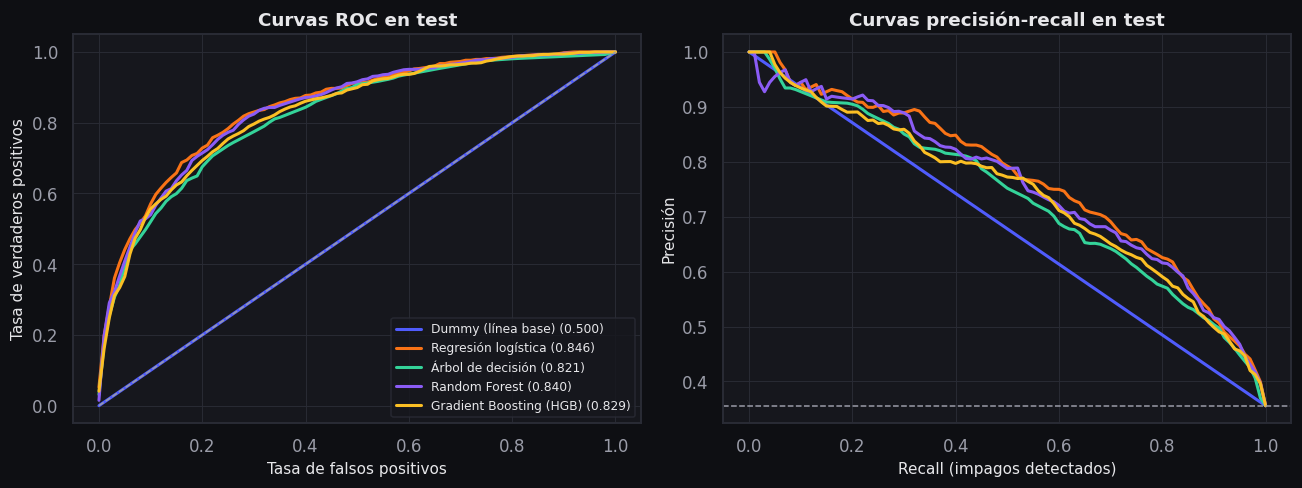

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for (nombre, p), color in zip(probs.items(), SERIE):
    c = curvas(y_te, p)
    ax[0].plot(c["fpr"], c["tpr"], color=color, lw=2, label=f"{nombre} ({tabla_test.loc[nombre, 'roc_auc']:.3f})")
    ax[1].plot(c["recall"], c["precision"], color=color, lw=2, label=nombre)
ax[0].plot([0, 1], [0, 1], ls="--", color=PALETA["texto_suave"], lw=1)
ax[0].set(title="Curvas ROC en test", xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos")
ax[1].axhline(y_te.mean(), ls="--", color=PALETA["texto_suave"], lw=1)
ax[1].set(title="Curvas precisión-recall en test", xlabel="Recall (impagos detectados)", ylabel="Precisión")
ax[0].legend(fontsize=8, loc="lower right")
plt.show()
cs = {n: curvas(y_te, p) for n, p in probs.items()}
figura_front("curva_roc", "Curvas ROC en test",
             {"series": [{"nombre": f"{n} ({tabla_test.loc[n, 'roc_auc']:.3f})", "x": c["fpr"], "y": c["tpr"]} for n, c in cs.items()],
              "referencias": [{"tipo": "diagonal", "etiqueta": "Azar"}]},
             ejes={"x": "Tasa de falsos positivos", "y": "Tasa de verdaderos positivos"}, clave="roc_clasicos")
figura_front("curva_pr", "Curvas precisión-recall en test",
             {"series": [{"nombre": n, "x": c["recall"], "y": c["precision"]} for n, c in cs.items()],
              "referencias": [{"eje": "y", "valor": round(float(y_te.mean()), 4), "etiqueta": "Prevalencia"}]},
             ejes={"x": "Recall (impagos detectados)", "y": "Precisión"}, clave="pr_clasicos")

**Interpretación.** Todos los modelos entrenados quedan muy por encima de la diagonal; la línea base
coincide con ella (AUC 0,50). La regresión logística (AUC 0,846) y el Random Forest (0,840) casi se
superponen, mientras que el árbol (0,821) y el boosting con hiperparámetros por defecto (0,829) quedan por
debajo: con estos datos un modelo lineal capta casi toda la señal. En precisión-recall, la línea punteada es
la prevalencia (35,6 %), lo que obtendría un clasificador sin información; la logística alcanza PR-AUC 0,768.

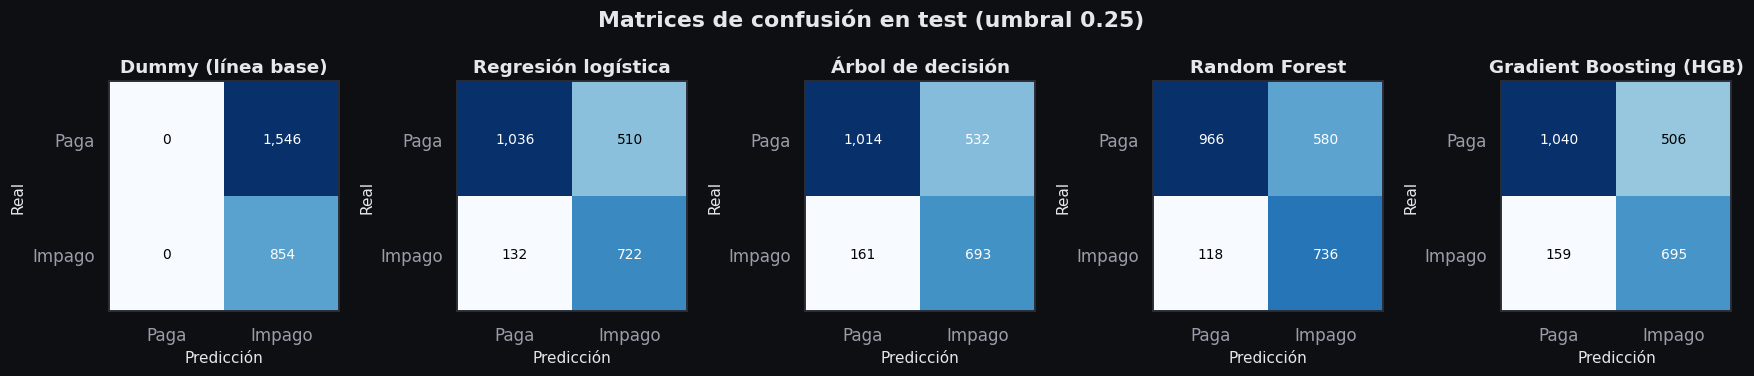

In [8]:
fig, axes = plt.subplots(1, len(probs), figsize=(16, 3.4))
for ax, (nombre, p) in zip(axes, probs.items()):
    cm = confusion_matrix(y_te, (p >= UMBRAL).astype(int))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=9)
    ax.set(title=nombre, xticks=[0, 1], yticks=[0, 1], xticklabels=["Paga", "Impago"], yticklabels=["Paga", "Impago"],
           xlabel="Predicción", ylabel="Real")
    ax.grid(False)
plt.suptitle(f"Matrices de confusión en test (umbral {UMBRAL:.2f})", fontweight="bold")
plt.show()
for k, (nombre, p) in enumerate(probs.items()):
    figura_front("matriz_confusion", f"Matriz de confusión · {nombre}",
                 {"etiquetas": ["Paga", "Impago"], "valores": confusion_matrix(y_te, (p >= UMBRAL).astype(int)).tolist()},
                 ejes={"x": "Predicción", "y": "Real"}, clave=f"confusion_modelo_{k}", nota=f"{nombre} · umbral {UMBRAL:.2f}")

**Interpretación.** Con el umbral de costo 0,25 los modelos priorizan detectar impagos (un falso negativo
cuesta tres veces más que un falso positivo): la logística detecta el 84,5 % de los impagos (recall) con una
precisión del 58,6 %. La línea base asigna a todos la prevalencia (0,356 ≥ 0,25), así que marca a todos como
impago: una sola columna ocupada, recall 1 y precisión igual a la prevalencia.

## 3. Interpretabilidad

Coeficientes de la regresión logística (variables estandarizadas: comparables entre sí) e importancia
por permutación (caída del AUC al desordenar una variable).

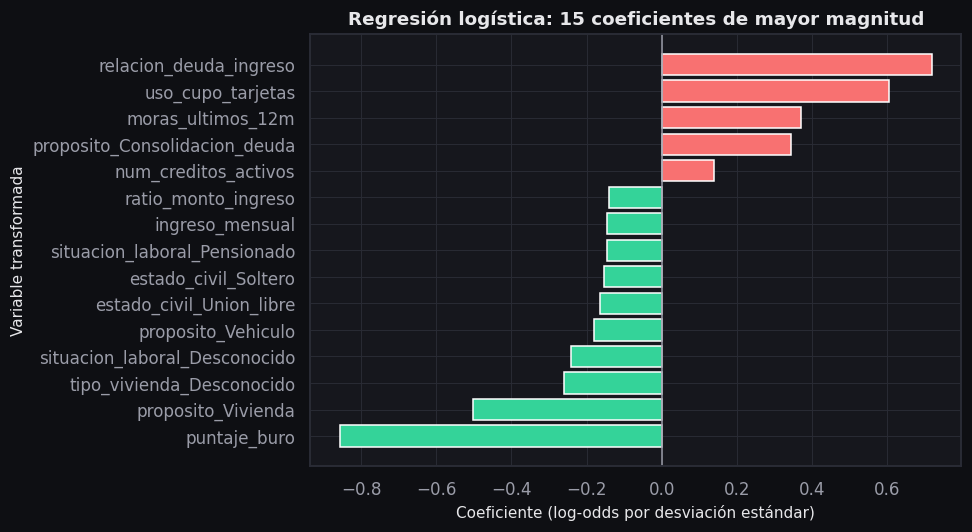

In [9]:
lr = modelos["Regresión logística"]
nombres = lr.named_steps["preprocessor"].get_feature_names_out()
coef = pd.DataFrame({"variable": nombres, "coeficiente": lr.named_steps["model"].coef_[0]})
coef["abs"] = coef["coeficiente"].abs()
top = coef.nlargest(15, "abs").sort_values("coeficiente")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["variable"], top["coeficiente"], color=np.where(top["coeficiente"] > 0, PALETA["alto"], PALETA["bajo"]))
ax.axvline(0, color=PALETA["texto_suave"], lw=1)
ax.set(title="Regresión logística: 15 coeficientes de mayor magnitud", xlabel="Coeficiente (log-odds por desviación estándar)",
       ylabel="Variable transformada")
plt.show()
figura_front("barras_h", "Regresión logística: 15 coeficientes de mayor magnitud",
             {"categorias": top["variable"].tolist(), "series": [{"nombre": "Coeficiente", "valores": top["coeficiente"].round(4).tolist()}]},
             ejes={"x": "Coeficiente (log-odds por desviación estándar)", "y": "Variable"}, clave="coeficientes_lr",
             opciones={"color_por": "signo"})

**Interpretación.** En rojo, lo que **aumenta** el riesgo; en verde, lo que lo **reduce**. Dominan el puntaje
de buró (−0,86 por desviación estándar), la relación deuda/ingreso (+0,72), el uso del cupo de tarjetas (+0,60)
y las moras recientes (+0,37), coherente con el negocio de crédito. El propósito *Vivienda* tiene coeficiente
negativo aunque su tasa bruta de impago es alta: es un efecto **condicional** (su riesgo ya lo explican el
monto y la carga financiera), no marginal. El sexo no participa en el modelo.

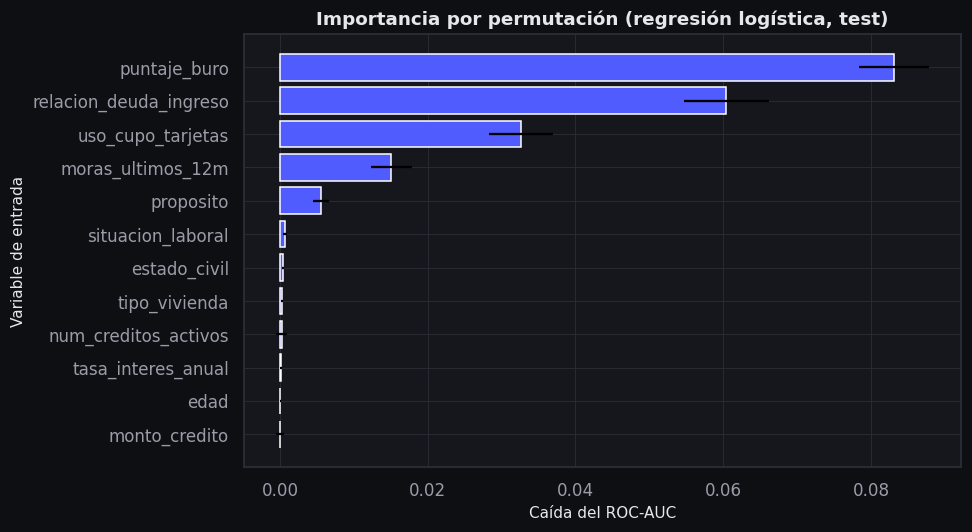

In [10]:
imp = importancia_permutacion(modelos["Regresión logística"], X_te, y_te, n_repeats=2 if FAST else 5,
                              muestra=800 if FAST else 2400)
fig, ax = plt.subplots(figsize=(9, 5))
d = imp.head(12).iloc[::-1]
ax.barh(d["variable"], d["importancia"], xerr=d["desviacion"], color=PALETA["acento"])
ax.set(title="Importancia por permutación (regresión logística, test)", xlabel="Caída del ROC-AUC", ylabel="Variable de entrada")
plt.show()
figura_front("barras_h", "Importancia por permutación (regresión logística, test)",
             {"categorias": d["variable"].tolist(), "series": [{"nombre": "Caída del ROC-AUC", "valores": d["importancia"].round(5).tolist(),
                                                               "errores": d["desviacion"].round(5).tolist()}]},
             ejes={"x": "Caída del ROC-AUC", "y": "Variable de entrada"}, clave="permutacion_lr")

**Interpretación.** La permutación confirma el ranking con una métrica independiente de los coeficientes:
desordenar el puntaje de buró hace caer el AUC en 0,083, la deuda/ingreso en 0,060, el uso de cupo en 0,033 y
las moras en 0,015; la edad y las demás variables demográficas quedan prácticamente en cero. Cuatro variables
financieras concentran casi toda la capacidad de discriminación.

## 4. Resultados para la comparación global (pasos 6, 7 y 8)

In [11]:
familia = {"Dummy (línea base)": "línea base"}
interp = {"Dummy (línea base)": "alta", "Regresión logística": "alta", "Árbol de decisión": "alta",
          "Random Forest": "media", "Gradient Boosting (HGB)": "media"}
cv_idx = tabla_cv.set_index("modelo")
filas = [FilaModelo(modelo=n, familia=familia.get(n, "clásico"), roc_auc_cv=round(float(cv_idx.loc[n, "roc_auc_cv"]), 4),
                    roc_auc_cv_std=round(float(cv_idx.loc[n, "roc_auc_cv_std"]), 4),
                    test=Metricas(**metricas(y_te, probs[n], UMBRAL)), tiempo_entrenamiento_s=round(tiempos[n], 2),
                    interpretabilidad=interp[n]) for n in tabla_cv["modelo"]]
cms = {n: confusion_matrix(y_te, (p >= UMBRAL).astype(int)).tolist() for n, p in probs.items()}
coef_out = [{"variable": r.variable, "original": variable_original(r.variable), "coeficiente": round(float(r.coeficiente), 5)}
            for r in coef.sort_values("abs", ascending=False).itertuples()]
res = ResultadosClasicos(notebook="05_modelos_clasicos.ipynb", umbral_metricas=UMBRAL, modelos=filas,
                         curvas={n: curvas(y_te, p) for n, p in probs.items()}, matrices_confusion=cms,
                         coeficientes_lr=coef_out,
                         importancia_permutacion=imp.round(5).to_dict(orient="records"))

## 5. Apéndice · Replicación de la metodología con datos reales (German Credit, UCI)

El dataset del proyecto es sintético-realista (E3). Para mostrar que la **metodología** (pipeline, CV en
train, métricas, auditoría de equidad) funciona igual sobre datos reales, se replica sobre *Statlog German
Credit* (1.000 solicitudes reales, UCI, licencia CC BY 4.0). No es una validación externa del modelo: las
variables son otras.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ruta_gc = config.EXTERNAL_DIR / "german_credit.csv"
if not ruta_gc.exists():
    from sklearn.datasets import fetch_openml

    config.EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)
    fetch_openml("credit-g", version=1, as_frame=True, parser="auto").frame.to_csv(ruta_gc, index=False)
gc = pd.read_csv(ruta_gc)
y_gc = (gc["class"] == "bad").astype(int).to_numpy()
X_gc = gc.drop(columns=["class"])
num_gc = X_gc.select_dtypes("number").columns.tolist()
cat_gc = [c for c in X_gc.columns if c not in num_gc]
pipe_gc = Pipeline([("pre", ColumnTransformer([("num", StandardScaler(), num_gc),
                                               ("cat", OneHotEncoder(handle_unknown="ignore"), cat_gc)])),
                    ("model", LogisticRegression(max_iter=3000))])
auc_gc = cross_validate(pipe_gc, X_gc, y_gc, cv=cv_estratificada(), scoring="roc_auc")["test_score"]
from sklearn.model_selection import cross_val_predict

p_gc = cross_val_predict(pipe_gc, X_gc, y_gc, cv=cv_estratificada(), method="predict_proba")[:, 1]
aprob = p_gc < umbrales_chow().aprobar
grupo = np.where(X_gc["age"] < 25, "menor de 25", "25 o más")
tasas = pd.Series(aprob).groupby(grupo).mean()
replica = {"filas": int(len(gc)), "prevalencia_mal_pagador": round(float(y_gc.mean()), 4),
           "roc_auc_cv_media": round(float(auc_gc.mean()), 4), "roc_auc_cv_std": round(float(auc_gc.std()), 4),
           "aprobacion_por_edad": {k: round(float(v), 4) for k, v in tasas.items()},
           "disparate_impact_edad": round(float(tasas.min() / tasas.max()), 4), "licencia": "CC BY 4.0 (UCI)"}
res.replicacion_german_credit = replica
replica

{'filas': 1000,
 'prevalencia_mal_pagador': 0.3,
 'roc_auc_cv_media': 0.7862,
 'roc_auc_cv_std': 0.0198,
 'aprobacion_por_edad': {'25 o más': 0.4524, 'menor de 25': 0.2483},
 'disparate_impact_edad': 0.5489,
 'licencia': 'CC BY 4.0 (UCI)'}

**Interpretación.** Sobre datos reales el mismo protocolo obtiene AUC 0,786 ± 0,020 (un dataset pequeño y más
difícil). La auditoría revela algo importante: con la misma política, los menores de 25 años se aprobarían
automáticamente el 24,8 % de las veces frente al 45,2 % de los mayores (DI 0,55). La disparidad por edad no es
un artefacto del dataset sintético: aparece con más fuerza en datos reales, y por eso la auditoría y la
mitigación del paso 8 son indispensables para implementar la solución (R4).

In [13]:
ruta = guardar_resultados(res, "resultados_clasicos")
mejor = tabla_cv.iloc[0]
display(Markdown(
    f"**Resumen calculado.** Mejor modelo en CV: **{mejor['modelo']}** (AUC CV {mejor['roc_auc_cv']:.4f} ± "
    f"{mejor['roc_auc_cv_std']:.4f}). En test: AUC {tabla_test.loc[mejor['modelo'], 'roc_auc']:.4f}, "
    f"KS {tabla_test.loc[mejor['modelo'], 'ks']:.4f}, Brier {tabla_test.loc[mejor['modelo'], 'brier']:.4f}. "
    f"Línea base: AUC {tabla_test.loc['Dummy (línea base)', 'roc_auc']:.4f}. "
    f"German Credit (real): AUC CV {replica['roc_auc_cv_media']:.4f}. Resultados en `{ruta.name}`."))

**Resumen calculado.** Mejor modelo en CV: **Regresión logística** (AUC CV 0.8578 ± 0.0050). En test: AUC 0.8459, KS 0.5445, Brier 0.1488. Línea base: AUC 0.5000. German Credit (real): AUC CV 0.7862. Resultados en `resultados_clasicos.json`.

## Conclusiones

1. **Todos los modelos superan con claridad a la línea base** (AUC 0,50) y a la meta del proyecto
   (AUC ≥ 0,70): el mejor alcanza 0,858 en CV y 0,846 en test, con KS 0,545.
2. **La regresión logística gana** en CV (0,8578 ± 0,005) y en test, entrena en menos de un segundo y es la
   más interpretable; el Random Forest queda cerca (0,853 en CV) y el boosting por defecto, por debajo. La
   selección se hizo solo con CV en train; test se usó una vez, después de congelarla.
3. **Cuatro variables financieras explican casi todo**: puntaje de buró, deuda/ingreso, uso de cupo y moras.
   Las demográficas aportan casi nada a la discriminación, lo que es deseable desde la ética.
4. **La metodología es trasladable**: replicada en German Credit (datos reales) obtiene AUC 0,786 y destapa una
   disparidad por edad fuerte (DI 0,55), que justifica la auditoría y la mitigación del paso 8.
5. Los resultados quedan en `resultados_clasicos.json` para la comparación con redes neuronales (paso 6), NLP
   (paso 7), Spark (paso 9) y el modelo servido (paso 8).